# Distance maps

A signed distance field (SDF) stores, for every pixel, the distance to the nearest object boundary: negative inside
of an object and positive outside. SDFs are used, for example, as regression targets for segmentation, or in
boundary-aware losses.

Unlike masks, the values of distance maps have a geometric meaning, so SOLT has a separate data type for them, `'D'`:

* They use **bilinear interpolation** by default, while masks use the nearest neighbour one.
* Their **values are rescaled** by the transforms that change the scale: `Scale`, `Shear`, `Projection`, `Resize` and
  `RandomResizedCrop`. This is exact for similarity transforms (rotation, uniform scaling, translation) and an
  approximation otherwise. Flips, rotations, translations and crops keep the values.
* **Zero padding** would create a false object boundary, so distance maps are padded with their `fill` value if it is
  set, and with their edge values otherwise.
* They can be `float16`, `float32` or `float64`, `HxW` or `HxWxC`. The result has the same dtype and shape.
  `float16` maps are processed in `float32` internally.

We use the same image of [scikit-image](https://scikit-image.org) as in the instance segmentation example.

In [1]:
%matplotlib inline
# JPEG keeps the notebook small, since the figures are photos
%config InlineBackend.figure_formats = ['jpeg']
import random

import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage as ndi
from skimage import color, data, filters, morphology

import solt
import solt.transforms as slt
import solt.utils as slu

# SOLT samples the transforms with the `random` module
random.seed(42)
np.random.seed(42)

## Getting the data

We segment two labels, the cell nuclei (blue) and the brown-stained tissue. `solt.utils.mask_to_sdf` computes a
signed distance field for each channel of the masks. Together, they make a multi-label distance map `HxWx2`,
which we store in `float16`.

In [2]:
img = data.immunohistochemistry()
hed = color.rgb2hed(img)
# Nuclei are stained by hematoxylin, the rest of the cells by DAB (brown)
hema = filters.gaussian(hed[..., 0], sigma=1)
dab = filters.gaussian(hed[..., 2], sigma=2)

nuclei = (hema > 1.15 * filters.threshold_otsu(hema)) & (dab < filters.threshold_otsu(dab))
nuclei = morphology.remove_small_holes(morphology.remove_small_objects(nuclei, max_size=60), max_size=60)
tissue = dab > filters.threshold_otsu(dab)
tissue = morphology.remove_small_holes(morphology.remove_small_objects(tissue, max_size=500), max_size=500)

label_names = ['Nuclei', 'Tissue']
masks = np.stack([nuclei, tissue], axis=-1).astype(np.uint8)
dmap = slu.mask_to_sdf(masks, dtype=np.float16)
print(f'Image: {img.shape} {img.dtype}, distance map: {dmap.shape} {dmap.dtype}')

Image: (512, 512, 3) uint8, distance map: (512, 512, 2) float16


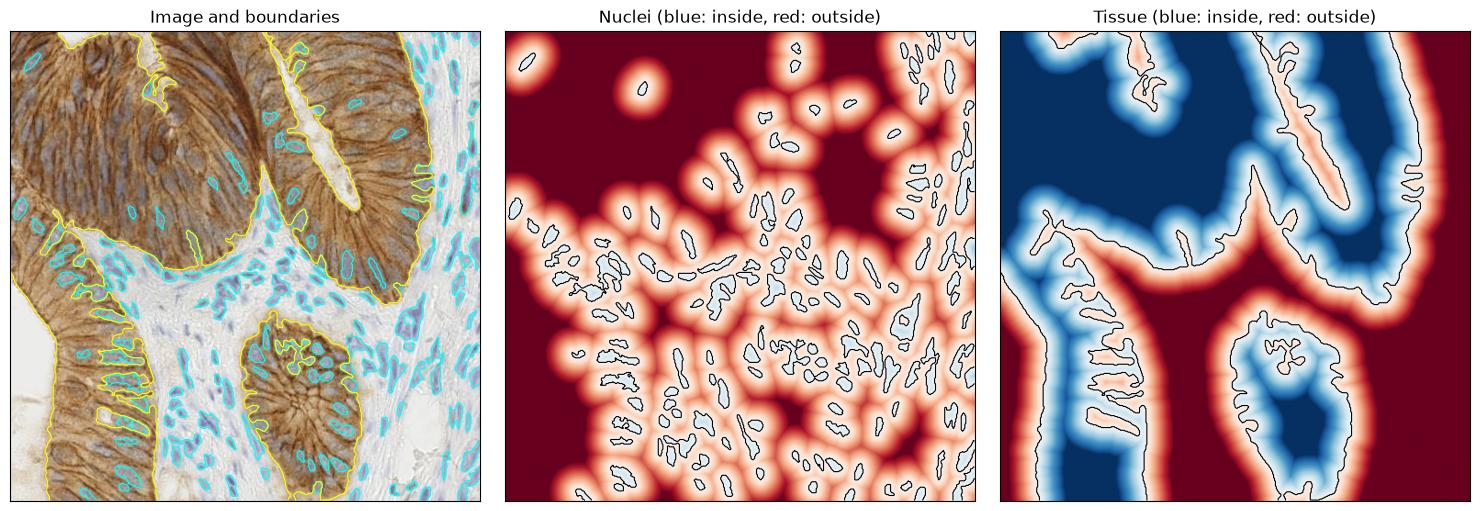

In [3]:
def show_dmap(ax, dmap, title=None, limit=30):
    """Shows a single-channel distance map (clipped to +-limit) and its zero level, i.e. the object boundaries."""
    dmap = dmap.astype(np.float32)
    ax.imshow(dmap, cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.contour(dmap, levels=[0], colors='k', linewidths=0.8)
    ax.set_xticks([])
    ax.set_yticks([])
    if title is not None:
        ax.set_title(title)


def show_boundaries(ax, img, dmap):
    """Shows an image together with the zero level of every channel of a distance map."""
    ax.imshow(img)
    for c, colour in zip(range(dmap.shape[2]), ['cyan', 'yellow']):
        ax.contour(dmap[..., c].astype(np.float32), levels=[0], colors=colour, linewidths=0.8)
    ax.set_xticks([])
    ax.set_yticks([])


fig, ax = plt.subplots(1, 3, figsize=(15, 5))
show_boundaries(ax[0], img, dmap)
ax[0].set_title('Image and boundaries')
for c, name in enumerate(label_names):
    show_dmap(ax[c + 1], dmap[..., c], f'{name} (blue: inside, red: outside)')
plt.tight_layout()
plt.show()

## Augmenting the image and the distance map

Distance maps go under the key `distance_map` (or `distance_maps` for several of them) in the dict API, and have
the format `'D'` in a `DataContainer`. These are their default settings:

In [4]:
dc = solt.DataContainer((img, dmap), 'ID')
dc.transform_settings[1]

{'interpolation': ('bilinear', 'strict'),
 'padding': ('z', 'inherit'),
 'fill': None}

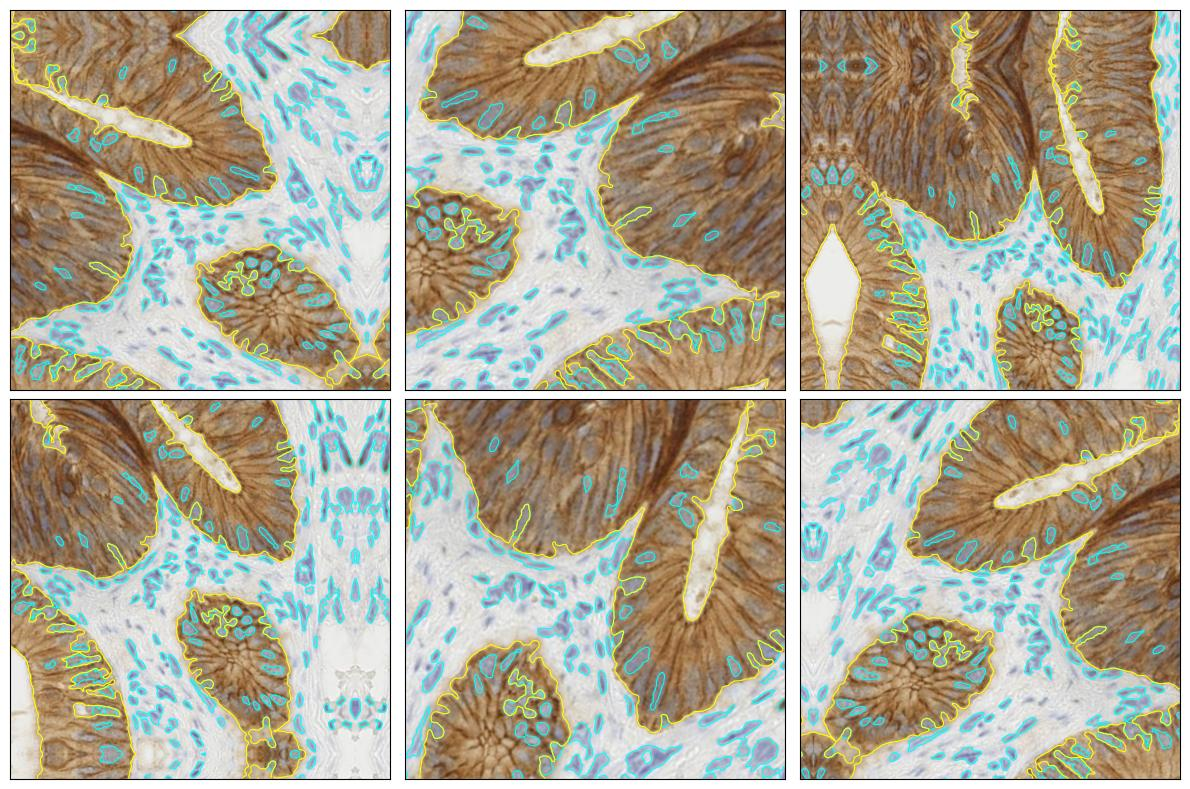

In [5]:
# Reflective padding treats the image and the distance map the same way (see the padding section below)
stream = solt.Stream([
    slt.Rotate(angle_range=(-45, 45), p=1, padding='r'),
    slt.Scale(range_x=(0.7, 1.4), p=1, padding='r'),
    slt.Flip(p=0.5),
    slt.Crop(384, crop_mode='r'),
])

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax in axes.ravel():
    img_res, dmap_res = stream({'image': img, 'distance_map': dmap}, return_torch=False).data
    show_boundaries(ax, img_res, dmap_res)
plt.tight_layout()
plt.show()

## Are the values right?

Let's augment the masks together with the distance map, and compare the augmented distance map with the one
computed from scratch from the augmented masks. The latter is a reference of only pixel accuracy, since the masks
have pixel steps. We compare the pixels close to the boundaries (less than 20 px), which are far enough from the
padded areas, so that the padding cannot affect the reference.

For comparison, the last column shows the error that we would have if the values were not rescaled.

In [6]:
transforms = {
    'Rotate 30°': slt.Rotate(angle_range=(30, 30), p=1),
    'Scale 0.6': slt.Scale(range_x=(0.6, 0.6), p=1),
    'Scale 1.7': slt.Scale(range_x=(1.7, 1.7), p=1),
    'Resize 0.5': slt.Resize(resize_to=(256, 256)),
    'Shear 0.3': slt.Shear(range_x=(0.3, 0.3), range_y=(0, 0), p=1),
    'Projection': slt.Projection(v_range=(5e-4, 5e-4), p=1),
}

print(f"{'Transform':12s} {'Scale':>6s} {'Error, px':>10s} {'Without rescaling, px':>22s}")
for name, trf in transforms.items():
    masks_res, dmap_res = trf(solt.DataContainer((masks, dmap), 'MD')).data
    dmap_res = dmap_res.astype(np.float32)
    # The factor, by which the values were rescaled
    scale = trf.distance_scale() if hasattr(trf, 'distance_scale') else masks_res.shape[0] / masks.shape[0]

    # Pixels, which come from the original image (not from the padding)
    inside = trf(solt.DataContainer((np.ones(masks.shape[:2], np.uint8),), 'M')).data[0] > 0
    distance_to_padding = ndi.distance_transform_edt(inside)

    errors, errors_unscaled = [], []
    for c in range(masks.shape[2]):
        reference = slu.mask_to_sdf(masks_res[..., c], dtype=np.float64)
        valid = (distance_to_padding > np.abs(reference) + 2) & (np.abs(reference) < 20)
        errors.append(np.abs(dmap_res[..., c] - reference)[valid])
        errors_unscaled.append(np.abs(dmap_res[..., c] / scale - reference)[valid])
    print(f'{name:12s} {scale:6.2f} {np.concatenate(errors).mean():10.2f} {np.concatenate(errors_unscaled).mean():22.2f}')

Transform     Scale  Error, px  Without rescaling, px


Rotate 30°     1.00       0.24                   0.24
Scale 0.6      0.60       0.25                   4.52
Scale 1.7      1.70       0.48                   3.23
Resize 0.5     0.50       0.35                   6.71
Shear 0.3      1.00       0.82                   0.82
Projection     1.00       0.81                   0.81


Without rescaling, the scaling transforms would be off by several pixels. With it, the errors of the similarity
transforms are at the level of the pixel accuracy of the reference. Shear and projection change the distances
differently in different directions, which a single factor cannot capture, so the augmented distance maps are
approximate for them. Here, the error stays below a pixel.

## Padding

When a transform brings in the areas from outside of the image, a distance map with zero padding would get a false
object boundary there. By default, SOLT pads a distance map with its edge values instead. This does not create new
boundaries, but extends the objects, which touch the image border, straight outwards. If the distances outside of
the image are known, e.g. "far from any object", set them with the `fill` setting. Other padding modes, e.g. the
reflective one (`'r'`), are applied as for images, so the image and the distance map stay consistent.

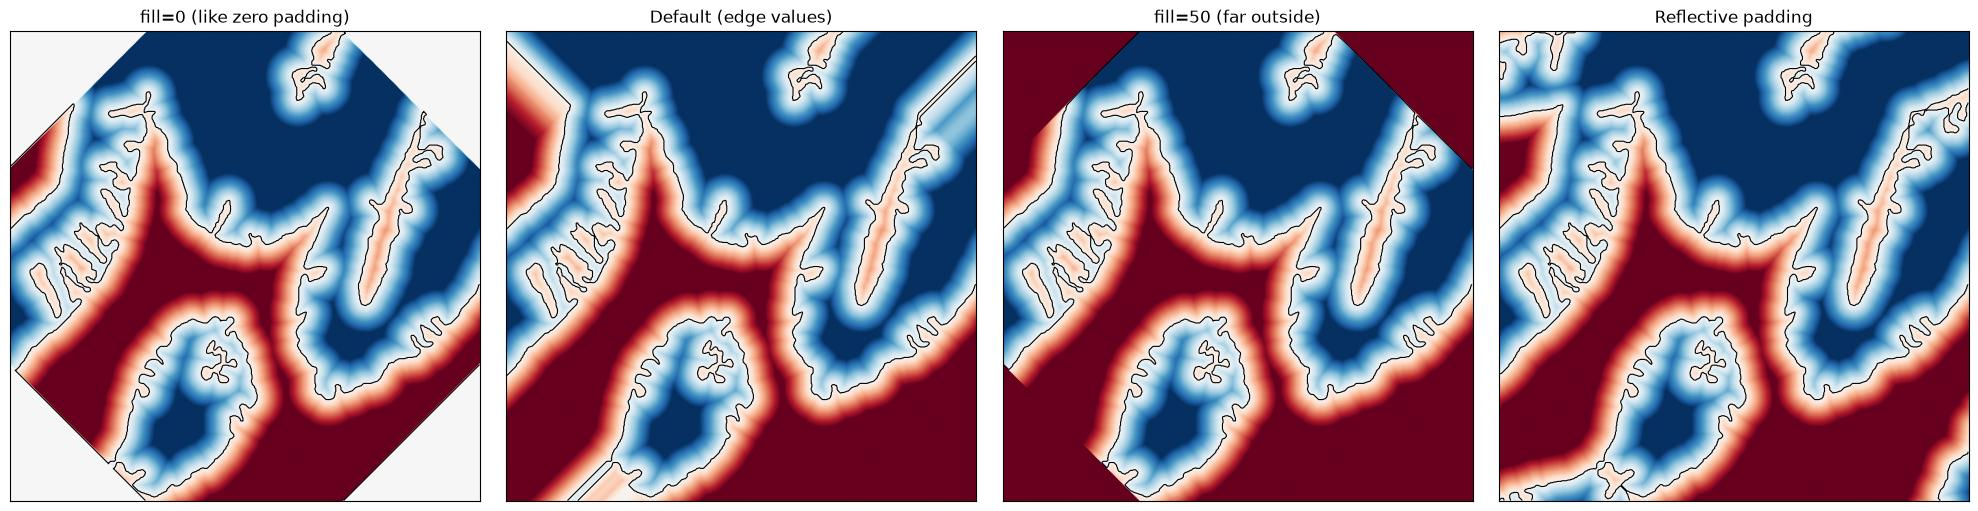

In [7]:
rotate = slt.Rotate(angle_range=(45, 45), p=1)
tissue_dmap = dmap[..., 1]
settings = {
    'fill=0 (like zero padding)': {0: {'fill': 0}},
    'Default (edge values)': None,
    'fill=50 (far outside)': {0: {'fill': 50}},
    'Reflective padding': {0: {'padding': 'r'}},
}

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (title, item_settings) in zip(axes, settings.items()):
    res = rotate(solt.DataContainer((tissue_dmap,), 'D', item_settings)).data[0]
    show_dmap(ax, res, title)
plt.tight_layout()
plt.show()

With `fill=0`, the zero level runs along the padded corners, i.e. the network would be taught that there are
object boundaries there.

## Converting to PyTorch

Distance maps become `CxHxW` `float32` tensors, the same as the multi-channel masks.

In [8]:
res = stream({'image': img, 'distance_map': dmap}, normalize=False)
{key: (tuple(value.shape), value.dtype) for key, value in res.items()}

{'image': ((3, 384, 384), torch.float32),
 'distance_map': ((2, 384, 384), torch.float32)}